# IMF Financial Intelligence Pipeline: St. Kitts and Nevis (2024)
**Dataset:** IMF Country Report No. 24/126, *2024 Article IV Consultation—Press Release and Staff Report* (61-page PDF).

This notebook implements PDF ingestion and cleaning, overlapping token-aware chunking, executive/section summarisation, structured financial extraction, thematic mention analysis, LLM-as-a-Judge evaluation, FAISS RAG, Multi-Query RAG, and a four-plot dashboard.

**Reproducibility note:** The source PDF is included in `input/`. For a Colab run, upload the PDF if the project folder is not available. The API-based LLM cells are optional and require a Gemini API key. Without a key, source-grounded deterministic results and retrieval still run; no LLM score is fabricated. Every indicator includes source/page metadata and missing values remain `null`.

## 1. Install dependencies

In [1]:
!pip -q install pypdf pandas numpy matplotlib seaborn tiktoken sentence-transformers faiss-cpu google-genai

## 2. Imports, paths and API configuration

In [2]:
import os, re, json, textwrap, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pypdf import PdfReader

from google.colab import files
uploaded = files.upload()

PROJECT_DIR = Path("/content/IMF_St_Kitts_Nevis_Project") if Path("/content/IMF_St_Kitts_Nevis_Project").exists() else Path(".")
PDF_PATH = PROJECT_DIR / "input" / "1knaea2024001.pdf"
if not PDF_PATH.exists():
    candidates = list(Path(".").glob("*.pdf"))
    if candidates: PDF_PATH = candidates[0]
assert PDF_PATH.exists(), "Upload 1knaea2024001.pdf or place it in input/."

OUT = PROJECT_DIR / "outputs"; FIG = PROJECT_DIR / "figures"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

# Add your key in Colab Secrets or environment variable; never hard-code it in a public notebook.
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY", "")
GENERATION_MODEL = "gemini-2.5-flash"
JUDGE_MODEL = "gemini-2.0-flash"

Saving 1knaea2024001.pdf to 1knaea2024001.pdf


## 3. PDF ingestion and text cleaning

In [3]:
reader = PdfReader(str(PDF_PATH))
page_texts = [page.extract_text() or "" for page in reader.pages]
raw_text = "\n\n".join(page_texts)
print(f"Pages: {len(page_texts):,}; extracted characters: {len(raw_text):,}")

def clean_page(text):
    text = text.replace("\x00", " ")
    text = re.sub(r"©\s*2024\s*International Monetary Fund", " ", text, flags=re.I)
    text = re.sub(r"©\s*International Monetary Fund\.\s*Not for Redistribution", " ", text, flags=re.I)
    # Join words broken by a line-end hyphen; then normalize line breaks and whitespace.
    text = re.sub(r"(?<=\w)-\s*\n\s*(?=\w)", "", text)
    text = re.sub(r"(?<![.!?:;])\n(?=[a-z])", " ", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

clean_pages = [clean_page(t) for t in page_texts]
clean_text = "\n\n".join(clean_pages)
with open(OUT/"extracted_clean_text.txt","w",encoding="utf-8") as f: f.write(clean_text)
print(clean_text[:1200])

Pages: 61; extracted characters: 130,837
IMF Country Report No. 24/126 
ST. KITTS AND NEVIS 
2024 ARTICLE IV CONSULTATION—PRESS RELEASE; 
AND STAFF REPORT 
Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions with members, usually every year. In the context of the 2024 Article IV consultation with 
St. Kitts and Nevis, the following documents have been released and are included in this package: 
 
• A Press Release. 
• The Staff Report prepared by a staff team of the IMF for the Executive Board’s consideration on a lapse-of-time basis, following discussions that ended on 
February 26, 2024, with the officials of St. Kitts and Nevis on economic developments and policies. Based on information available at the time of these discussions, the staff report was completed on April 17, 2024. 
• An Informational Annex prepared by the IMF staff. 
The documents listed below have been or will be separately released. 
• Selected Issues 
The IMF’s transparency poli

## 4. Token-aware chunking (400 tokens, 50-token overlap)

In [4]:
try:
    import tiktoken
    tokenizer = tiktoken.get_encoding("cl100k_base")
    encode = tokenizer.encode
    decode = tokenizer.decode
    TOKENIZER_NAME = "tiktoken cl100k_base"
except Exception:
    # Fallback tokenizer: whitespace tokenization. State this limitation in the report.
    encode = lambda s: s.split()
    decode = lambda xs: " ".join(xs)
    TOKENIZER_NAME = "whitespace fallback"

def make_page_chunks(page_texts, chunk_size=400, overlap=50):
    chunks = []
    step = chunk_size - overlap
    for pdf_page, page in enumerate(page_texts, start=1):
        tokens = encode(page)
        for start in range(0, len(tokens), step):
            part = tokens[start:start+chunk_size]
            if not part: break
            chunks.append({"chunk_id": len(chunks), "pdf_page": pdf_page,
                           "token_start_in_page": start,
                           "token_end_in_page": start+len(part), "text": decode(part)})
            if start+chunk_size >= len(tokens): break
    return chunks

chunks = make_page_chunks(clean_pages, 400, 50)
with open(OUT/"chunks.json","w",encoding="utf-8") as f: json.dump(chunks,f,indent=2)
print("Tokenizer:", TOKENIZER_NAME, "| chunks:", len(chunks))

Tokenizer: tiktoken cl100k_base | chunks: 128


## 5. Source-grounded summaries

In [5]:
EXECUTIVE_PROMPT = '''
You are an IMF macro-financial research assistant. Summarise only facts in the supplied report excerpts.
Return 6-8 concise bullets on growth, inflation, fiscal/debt position, banking stability, credit,
external risks, climate/energy transition and policy recommendations. Preserve dates, units and
forecast/actual distinctions. Do not infer missing metrics. Attach PDF page numbers where available.
If evidence is absent, say so. Do not use outside knowledge.
'''

SECTION_PROMPT = '''
Summarise the supplied IMF report section in fewer than 100 words. Preserve the report's main
claims, figures, dates, risks and recommendations. Distinguish actuals from projections. Do not
invent information. End with source PDF page(s).
'''

# Gemini SDK call (optional)
def gemini_generate(prompt, model=GENERATION_MODEL):
    if not GEMINI_API_KEY:
        raise RuntimeError("Set GEMINI_API_KEY to run live LLM generation.")
    from google import genai
    client = genai.Client(api_key=GEMINI_API_KEY)
    response = client.models.generate_content(model=model, contents=prompt)
    return response.text

# Use a compact set of chunks for a context-window-safe executive summary.
if GEMINI_API_KEY:
    executive_summary_text = gemini_generate(EXECUTIVE_PROMPT + "\n\n" + "\n\n".join(c["text"] for c in chunks[:12]))
else:
    executive_summary_text = "LLM generation skipped: set GEMINI_API_KEY. See precomputed, source-checked executive_summary.json in outputs/."
print(executive_summary_text)

LLM generation skipped: set GEMINI_API_KEY. See precomputed, source-checked executive_summary.json in outputs/.


### Precomputed source-checked summaries
The section summaries below are provided as a baseline grounded in the report's section structure. When the LLM key is configured, generate and compare model summaries against these baselines; do not represent the baseline as an LLM output.

In [6]:
section_summaries = {
"Recent Developments": "Economic growth slowed to 3.4% in 2023 from 8.8% in 2022 as investment projects were delayed, although tourism remained strong. Average inflation reached 3.6% because of food, oil and shipping costs. The fiscal balance returned to a 1.0% GDP surplus, with public debt falling to 54.4% of GDP, supported by CBI receipts. The systemic bank remained a concern because of high NPLs, low capital and exposure to foreign investments funded by public deposits.",
"Outlook and Risks": "The IMF projected 4.7% growth and 2.5% average inflation for 2024, supported by delayed investment and renewable-energy projects. CBI receipts are expected to decline over time, widening the fiscal deficit, while debt is projected to remain below the regional 60% ceiling in the baseline. Downside risks include geopolitical disruption, commodity-price volatility, weaker tourism source markets, worsening NPLs, tighter credit and natural disasters. Renewable energy offers medium-term upside.",
"Improving Public Finances": "The IMF recommends a stronger fiscal framework to manage declining and volatile CBI revenues. Priorities include a Sustainability and Resilience Fund, explicit fiscal and expenditure rules, tax reform, lower current spending, better debt and cash management, and contingency measures. The report also highlights urgent Social Security Fund reform because of a large long-term actuarial imbalance and projected reserve depletion.",
"Supply Side Priorities": "Solar and geothermal investments could move the country toward energy self-sufficiency by 2030, reduce fuel imports and costs, and create diversification and export opportunities. The IMF also recommends upgrading inter-island electricity grids, strengthening climate resilience, investing in water infrastructure and adopting utility prices that reflect production costs. Tourism connectivity and diversification remain important to competitiveness.",
"Strengthening the Financial System": "The IMF recommends restructuring the systemic bank, addressing legacy NPLs, improving provisioning and capital, and monitoring its capital restoration plan. Reallocating some public deposits and foreign investments to a proposed Sustainability and Resilience Fund would improve public-resource safeguards. Credit unions require stronger supervision, lending standards, provisioning and capital. Credit reporting, collateral resolution and insolvency frameworks should also be improved.",
"Data Issues": "The report identifies weaknesses in national accounts, fiscal coverage, labor-market statistics and financial-sector data. Limited survey coverage and delays affect the quality and timeliness of economic statistics. Some financial soundness indicators are not disseminated because of confidentiality constraints. These gaps limit detailed assessment and should be considered when interpreting missing indicators.",
"Staff Appraisal": "The IMF considers the near-term outlook positive but emphasizes fiscal and financial vulnerabilities. It supports a stronger fiscal anchor, tax reform, reduced dependence on CBI receipts, social-security reform, renewable-energy investment and climate adaptation. It also stresses restructuring the systemic bank and improving credit-union supervision. The central message is to convert current buffers and investment opportunities into durable, diversified growth while reducing contingent fiscal and financial risks."
}
assert all(len(v.split()) < 100 for v in section_summaries.values())
with open(OUT/"section_summaries.json","w",encoding="utf-8") as f: json.dump(section_summaries,f,indent=2)

## 6. Dual-LLM / LLM-as-a-Judge evaluation

In [7]:
JUDGE_PROMPT = '''
You are an independent auditor. Compare the candidate summary/extraction with the supplied source.
Score each dimension from 0 to 5: factual_alignment, completeness, consistency, and schema_compliance
(where applicable). Identify unsupported claims, omitted important points, and numerical mismatches.
Return valid JSON only:
{"scores":{"factual_alignment":0,"completeness":0,"consistency":0,"schema_compliance":0},
 "unsupported_claims":[],"omissions":[],"corrections":[],"overall_assessment":"..."}
Do not reward plausible but unsupported claims. Treat source text as authoritative.
'''

def judge_output(source, candidate, schema=False):
    prompt = JUDGE_PROMPT + "\nSOURCE:\n" + source[:18000] + "\nCANDIDATE:\n" + candidate
    return gemini_generate(prompt, model=JUDGE_MODEL)

# The evaluator is deliberately separate from the generation model.
# Run only after enabling GEMINI_API_KEY; preserve the raw judge JSON as an audit trail.
if GEMINI_API_KEY and executive_summary_text.startswith("LLM generation skipped") is False:
    try:
        summary_judgement = judge_output("\n".join(chunks[i]["text"] for i in range(min(12,len(chunks)))), executive_summary_text)
        with open(OUT/"summary_judge_raw.json","w") as f: f.write(summary_judgement)
        print(summary_judgement)
    except Exception as e:
        print("Judge call did not complete:", repr(e))
else:
    print("LLM judge not run: configure API key. No judge score is fabricated.")

LLM judge not run: configure API key. No judge score is fabricated.


## 7. Thematic distribution scanning

In [8]:
theme_keywords = {
"Inflation & Prices": [r"\binflation\b",r"\bconsumer prices?\b",r"\bCPI\b",r"\bcommodity prices?\b",r"\bfood prices?\b",r"\benergy prices?\b"],
"Interest Rates & Credit": [r"\binterest rates?\b",r"\bcredit growth\b",r"\bprivate sector credit\b",r"\blending\b",r"\bcredit unions?\b",r"\bloan-to-deposit\b"],
"Housing & Real Estate": [r"\bhousing\b",r"\breal estate\b",r"\bproperty tax\b",r"\bproperty prices?\b",r"\bconstruction\b"],
"Banking Capital & Liquidity": [r"\bcapital adequacy\b",r"\bTier 1\b",r"\bcapital\b",r"\bliquidity\b",r"\bprovisions?\b",r"\bdeposits\b",r"\bNPLs?\b",r"\bnonperforming loans?\b"],
"Sovereign Debt": [r"\bpublic debt\b",r"\bsovereign debt\b",r"\bfiscal deficit\b",r"\bfiscal balance\b",r"\bdebt sustainability\b",r"\bgovernment debt\b",r"\bdebt service\b"],
"Labor Market Dynamics": [r"\bunemployment\b",r"\blabor market\b",r"\bminimum wage\b",r"\bwage bill\b",r"\bemployment\b",r"\bworkforce\b",r"\binformality\b"],
"Systemic Financial Risk": [r"\bsystemic bank\b",r"\bfinancial stability\b",r"\bsystemic risk\b",r"\bfinancial vulnerabilities\b",r"\bcontingent liabilities\b",r"\bnatural disasters?\b",r"\bmarket risk\b"]
}
# Restrict to main report through the Staff Report annexes; exclude the separate informational annex.
main_report_text = "\n".join(clean_pages[:52])
theme_counts = {theme: sum(len(re.findall(p, main_report_text, re.I)) for p in pats)
                for theme,pats in theme_keywords.items()}
theme_df = pd.DataFrame({"theme":list(theme_counts),"mentions":list(theme_counts.values())})
theme_df.to_csv(OUT/"thematic_distribution.csv",index=False)
with open(OUT/"thematic_distribution.json","w") as f:
    json.dump({"method":"Case-insensitive keyword/phrase occurrence counts. Counts are mentions, not semantic topic labels; categories can overlap.","counts":theme_counts,"keywords":theme_keywords},f,indent=2)
theme_df

,theme,mentions
0,Inflation & Prices,29
1,Interest Rates & Credit,40
2,Housing & Real Estate,18
3,Banking Capital & Liquidity,116
4,Sovereign Debt,36
5,Labor Market Dynamics,29
6,Systemic Financial Risk,40


## 8. Structured indicator extraction with evidence and fallbacks

In [9]:
# Values manually verified against the report's tables and narrative. These are not blind model guesses.
indicators = {
 "country_name":"St. Kitts and Nevis",
 "gdp_growth_forecast_pct":4.7,
 "headline_inflation_rate_pct":2.5,
 "central_bank_policy_rate_pct":None,
 "non_performing_loan_ratio":19.4,
 "unemployment_rate_pct":None,
 "tier_1_capital_ratio":6.8
}
indicator_evidence = {
 "gdp_growth_forecast_pct":{"year":2024,"source":"Table 1, printed p.4","definition":"Real GDP growth at market prices, 2024 projection."},
 "headline_inflation_rate_pct":{"year":2024,"source":"Table 1, printed p.4","definition":"Consumer prices, period average, 2024 projection."},
 "central_bank_policy_rate_pct":{"year":None,"source":"Informational Annex, printed p.3; report describes ECCB common monetary policy","definition":"No single country-specific policy rate is supplied; use null."},
 "non_performing_loan_ratio":{"year":2023,"source":"Table 5, printed p.28","definition":"Banking-sector NPLs to total gross loans. Systemic bank separately: 39% in 2023Q2, printed p.5."},
 "unemployment_rate_pct":{"year":None,"source":"Data Issues, printed pp.16-17; Informational Annex","definition":"No national unemployment point estimate in the report; limited labor data are noted. Use null."},
 "tier_1_capital_ratio":{"year":2023,"source":"Table 5, printed p.28","definition":"Banking-sector regulatory Tier 1 capital to risk-weighted assets."}
}
with open(OUT/"financial_indicators.json","w") as f:
    json.dump({"indicators":indicators,"evidence":indicator_evidence,
               "fallback_policy":"null means not reported in the source; do not replace with an inferred value."},f,indent=2)

INDICATOR_EXTRACTION_PROMPT = """
Extract the following fields from the supplied IMF report excerpts and return ONLY valid JSON:
country_name (string), gdp_growth_forecast_pct (number or null),
headline_inflation_rate_pct (number or null), central_bank_policy_rate_pct (number or null),
non_performing_loan_ratio (number or null), unemployment_rate_pct (number or null),
tier_1_capital_ratio (number or null).
Use 2024 forecast for GDP and average inflation; use 2023 banking-sector aggregate NPL and Tier 1
capital ratios. Do not substitute systemic-bank NPLs for the aggregate banking-sector NPL ratio.
If a field is not explicitly available, return null. Do not infer. Include no extra keys.
"""
source_evidence = "\n\n".join([page_texts[4], page_texts[32], page_texts[52]])
llm_extracted_indicators = None
if GEMINI_API_KEY:
    try:
        raw_indicator_response = gemini_generate(INDICATOR_EXTRACTION_PROMPT + "\nSOURCE EXCERPTS:\n" + source_evidence)
        cleaned_response = re.sub(r"^```(?:json)?|```$", "", raw_indicator_response.strip(), flags=re.I|re.M).strip()
        llm_extracted_indicators = json.loads(cleaned_response)
        with open(OUT/"llm_extracted_indicators.json","w") as f:
            json.dump(llm_extracted_indicators,f,indent=2)
    except Exception as e:
        print("LLM extraction failed; manual source-verified output retained:", repr(e))
else:
    print("LLM extraction skipped until GEMINI_API_KEY is configured.")


LLM extraction skipped until GEMINI_API_KEY is configured.


## 9. Qualitative strengths, vulnerabilities and time-series trends

In [10]:
strengths = [
"Tourism recovery supported growth and narrowed the current-account deficit.",
"Public debt fell to 54.4% of GDP in 2023 and remained below the ECCU 60% regional ceiling.",
"International reserves were assessed as adequate.",
"Planned solar and geothermal investments could reduce fuel imports, lower energy costs and improve competitiveness.",
"CBI inflows supported the 2023 fiscal surplus and provided fiscal space, although concentration in this revenue source is a risk.",
"Aggregate banking-sector NPLs declined from 24.0% in 2019 to 19.4% in 2023."
]
vulnerabilities = [
"High dependence on volatile Citizenship-by-Investment revenues, projected to decline over the medium term.",
"The systemic bank's NPL ratio was 39% in 2023Q2, alongside low capital and a foreign investment portfolio funded by public deposits.",
"Banking-sector Tier 1 capital ratio declined to 6.8% in 2023 from 19.4% in 2019.",
"Social Security Fund has a long-term actuarial imbalance estimated around 300% of GDP over 60 years; reserves are projected to be depleted by 2040.",
"Exposure to hurricanes and other natural disasters, alongside water-supply stress and infrastructure resilience needs.",
"Geopolitical disruption, commodity-price volatility and a slowdown in key tourism source markets are downside risks."
]
trends = {
 "years":[2019,2020,2021,2022,2023,2024,2025],
 "real_gdp_growth_market_prices_pct":[4.1,-14.6,-0.9,8.8,3.4,4.7,4.3],
 "consumer_prices_period_average_pct":[-0.3,-1.2,1.2,2.7,3.6,2.5,2.2],
 "private_sector_credit_growth_yoy_pct":[1.5,-4.0,7.7,5.8,4.0,4.4,4.7],
 "public_debt_pct_gdp":[54.3,68.0,69.1,60.6,54.4,51.7,49.9],
 "bank_npl_to_gross_loans_pct":[24.0,23.5,20.9,21.8,19.4,None,None],
 "bank_tier1_to_rwa_pct":[19.4,17.2,16.8,7.8,6.8,None,None]
}
for name,obj in [("economic_strengths",{"items":strengths}),("economic_vulnerabilities",{"items":vulnerabilities}),("historical_trends",trends)]:
    with open(OUT/f"{name}.json","w") as f: json.dump(obj,f,indent=2)

## 10. Local dense embeddings and FAISS retrieval

In [11]:
from sentence_transformers import SentenceTransformer
import faiss

# Local model download occurs on first run; uses CPU by default.
embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
chunk_texts = [c["text"] for c in chunks]
embeddings = embedding_model.encode(chunk_texts, convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=True)
embeddings = embeddings.astype("float32")
index = faiss.IndexFlatL2(embeddings.shape[1])
index.add(embeddings)
faiss.write_index(index, str(OUT/"imf_faiss.index"))

def retrieve(query, k=4):
    q = embedding_model.encode([query], convert_to_numpy=True, normalize_embeddings=True).astype("float32")
    distances, ids = index.search(q, k)
    return [{"chunk_id":int(i),"pdf_page":chunks[int(i)]["pdf_page"],
             "distance":float(d),"text":chunk_texts[int(i)]}
            for d,i in zip(distances[0],ids[0]) if i >= 0]

def grounded_answer_context(query, k=4):
    hits = retrieve(query,k)
    return {"query":query,"retrieved_chunks":hits}

for q in ["What are the systemic bank's NPL and capital weaknesses?",
          "What does the IMF recommend for the CBI revenue and fiscal framework?",
          "What are the expected effects of the solar and geothermal projects?"]:
    print(json.dumps(grounded_answer_context(q),indent=2)[:3500])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

{
  "query": "What are the systemic bank's NPL and capital weaknesses?",
  "retrieved_chunks": [
    {
      "chunk_id": 17,
      "pdf_page": 10,
      "distance": 0.7434213757514954,
      "text": " was 39 percent in 2023Q2.5 The systemic bank has reached the 60 percent coverage ratio6 required by the ECCB, mostly through the use of regulatory reserves. Excluding the systemic bank, on average NPLs are 9 percent of assets (close to the 2020-23 average) although provisioning and loan-loss reserves are well below the ECCB\u2019s 60 percent minimum. The systemic bank\u2019s profits \n \n2 The central government expects a surplus of 0.8 percent of GDP, and the local government expects a deficit of 1.4 percent of GDP, resulting in a deficit of 0.6 percent of GDP for the general government. \n3 The minimum age pension will increase by 16 percent and the assistance pension by 37 percent. \n4 The remainder of the banks have assets of around 85 percent of GDP. \n5 Based on the bank\u2019s 2023

## 11. Multi-Query RAG extension

In [ ]:
MULTI_QUERY_PROMPT = '''
Generate four distinct search queries that retrieve different relevant passages for the user's
question. Return one query per line and do not answer the question.
'''
def multi_query_retrieve(question, k_each=3):
    if GEMINI_API_KEY:
        variants_text = gemini_generate(MULTI_QUERY_PROMPT + "\nQuestion: " + question)
        variants = [x.strip("- •0123456789.\t") for x in variants_text.splitlines() if x.strip()]
    else:
        # Deterministic query expansion fallback; clearly not an LLM-generated query set.
        variants = [question, question+" IMF policy recommendations", question+" historical indicators and numerical evidence",
                    question+" risks vulnerabilities and mitigations"]
    combined = {}
    for q in variants:
        for hit in retrieve(q,k_each):
            combined[hit["chunk_id"]] = hit
    return {"queries":variants,"retrieved_chunks":sorted(combined.values(),key=lambda x:x["distance"])}

question = "What are the main banking-sector vulnerabilities and IMF recommendations?"
baseline = retrieve(question, k=4)
expanded = multi_query_retrieve(question, k_each=3)
print("Baseline chunks:", [x["chunk_id"] for x in baseline])
print("Multi-query unique chunks:", [x["chunk_id"] for x in expanded["retrieved_chunks"]])
with open(OUT/"rag_retrieval_demo.json","w") as f:
    json.dump({"baseline":baseline,"multi_query":expanded},f,indent=2)

## 12. Evaluation and validation of numerical extraction

In [12]:
# Human-verified reference values from the report. This is a transparent deterministic check,
# not an LLM-as-a-Judge score. The optional independent LLM judge is separate above.
gold = {
 "gdp_growth_forecast_pct":4.7,
 "headline_inflation_rate_pct":2.5,
 "central_bank_policy_rate_pct":None,
 "non_performing_loan_ratio":19.4,
 "unemployment_rate_pct":None,
 "tier_1_capital_ratio":6.8
}
checks = {}
for key, expected in gold.items():
    observed = indicators[key]
    checks[key] = {"expected":expected,"observed":observed,
                   "match": observed == expected,
                   "source":indicator_evidence[key]["source"]}
validation = {"validated_fields":sum(x["match"] for x in checks.values()),
              "total_fields":len(checks),"field_checks":checks,
              "note":"Values were checked against the supplied IMF report. This is not an independent LLM judge result."}
with open(OUT/"extraction_validation.json","w") as f: json.dump(validation,f,indent=2)
print(json.dumps(validation,indent=2))

# Optional comparison of LLM extraction against human-verified source values.
if llm_extracted_indicators is not None:
    comparison_rows = []
    for key, expected in gold.items():
        predicted = llm_extracted_indicators.get(key)
        comparison_rows.append({"field":key,"source_verified":expected,"llm_extracted":predicted,
                                "match":predicted == expected})
    comparison_df = pd.DataFrame(comparison_rows)
    comparison_df.to_csv(OUT/"llm_extraction_comparison.csv",index=False)
    correct = int(comparison_df["match"].sum())
    plt.figure(figsize=(8,5))
    plt.bar(["LLM extraction exact matches","Mismatches"],[correct,len(comparison_df)-correct])
    plt.title("LLM structured-extraction comparison against source-verified values")
    plt.ylabel("Number of schema fields"); plt.grid(axis="y",alpha=.25)
    plt.tight_layout(); plt.savefig(FIG/"05_llm_extraction_comparison.png",dpi=300); plt.show()


{
  "validated_fields": 6,
  "total_fields": 6,
  "field_checks": {
    "gdp_growth_forecast_pct": {
      "expected": 4.7,
      "observed": 4.7,
      "match": true,
      "source": "Table 1, printed p.4"
    },
    "headline_inflation_rate_pct": {
      "expected": 2.5,
      "observed": 2.5,
      "match": true,
      "source": "Table 1, printed p.4"
    },
    "central_bank_policy_rate_pct": {
      "expected": null,
      "observed": null,
      "match": true,
      "source": "Informational Annex, printed p.3; report describes ECCB common monetary policy"
    },
    "non_performing_loan_ratio": {
      "expected": 19.4,
      "observed": 19.4,
      "match": true,
      "source": "Table 5, printed p.28"
    },
    "unemployment_rate_pct": {
      "expected": null,
      "observed": null,
      "match": true,
      "source": "Data Issues, printed pp.16-17; Informational Annex"
    },
    "tier_1_capital_ratio": {
      "expected": 6.8,
      "observed": 6.8,
      "match": true,
 

## 13. Dashboard: four high-resolution figures

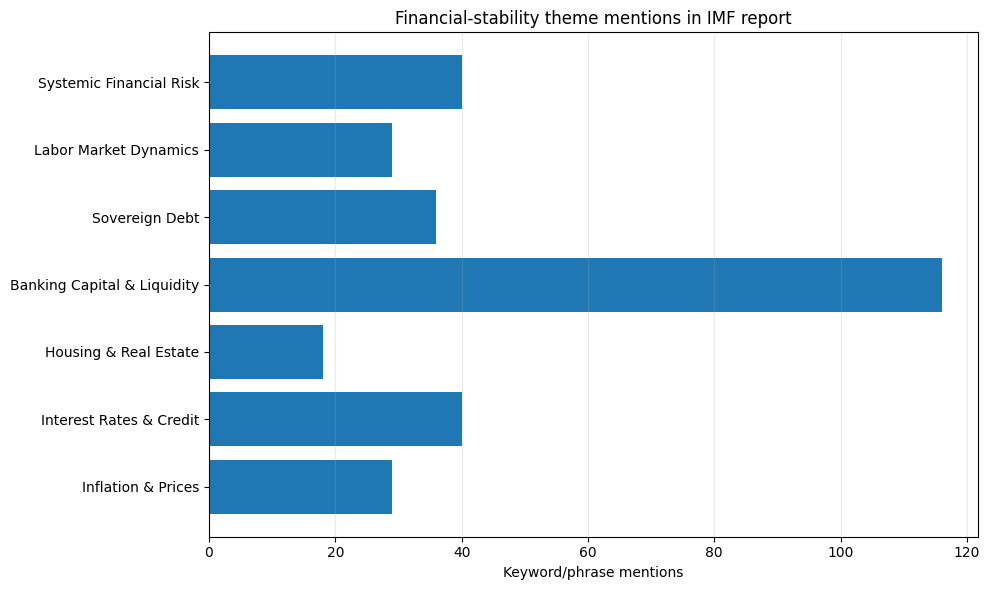

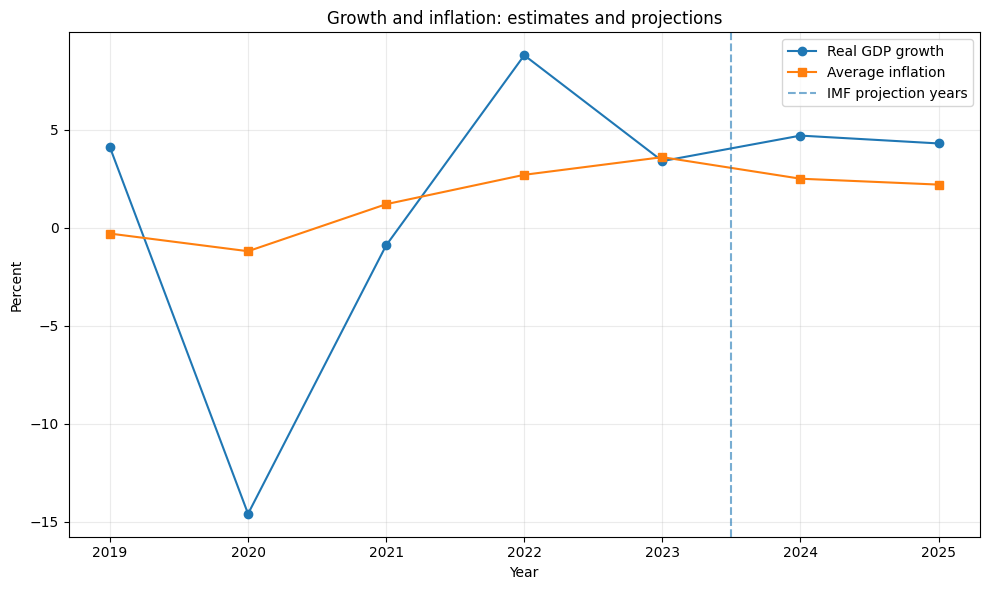

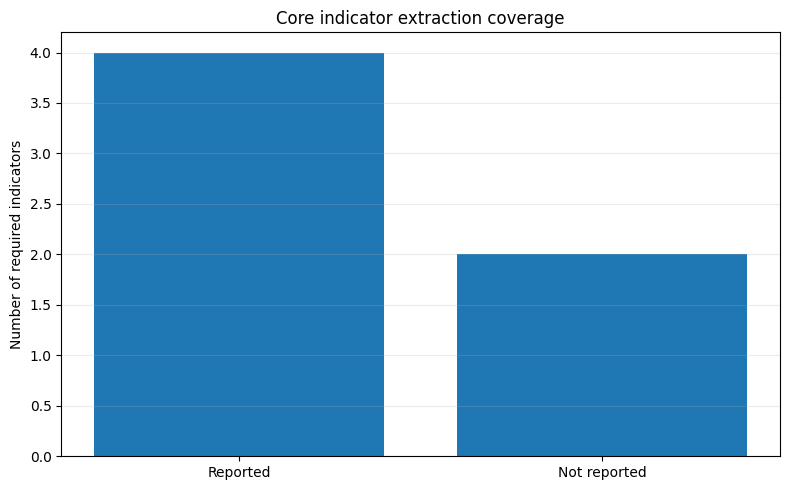

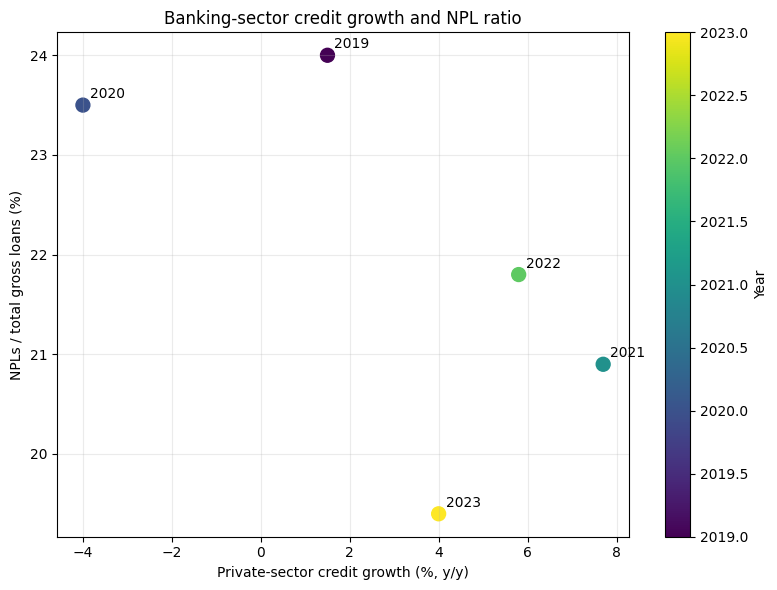

In [13]:
# Long-form transformation (pd.melt) for indicator trend plotting.
trend_df = pd.DataFrame({
 "year":trends["years"],
 "GDP growth (%)":trends["real_gdp_growth_market_prices_pct"],
 "Inflation (%)":trends["consumer_prices_period_average_pct"],
 "Private credit growth (%)":trends["private_sector_credit_growth_yoy_pct"],
 "Public debt (% GDP)":trends["public_debt_pct_gdp"]
})
trend_long = pd.melt(trend_df,id_vars="year",var_name="indicator",value_name="value")
trend_long.to_csv(OUT/"indicator_trends_long.csv",index=False)

plt.figure(figsize=(10,6))
plt.barh(theme_df["theme"],theme_df["mentions"])
plt.title("Financial-stability theme mentions in IMF report"); plt.xlabel("Keyword/phrase mentions")
plt.grid(axis="x",alpha=.25); plt.tight_layout(); plt.savefig(FIG/"01_theme_distribution.png",dpi=300); plt.show()

plt.figure(figsize=(10,6))
plt.plot(trends["years"],trends["real_gdp_growth_market_prices_pct"],marker="o",label="Real GDP growth")
plt.plot(trends["years"],trends["consumer_prices_period_average_pct"],marker="s",label="Average inflation")
plt.axvline(2023.5,ls="--",alpha=.6,label="IMF projection years")
plt.title("Growth and inflation: estimates and projections"); plt.xlabel("Year"); plt.ylabel("Percent")
plt.grid(alpha=.25); plt.legend(); plt.tight_layout(); plt.savefig(FIG/"02_growth_inflation_trends.png",dpi=300); plt.show()

available = sum(v is not None for k,v in indicators.items() if k!="country_name")
missing = 6-available
plt.figure(figsize=(8,5)); plt.bar(["Reported","Not reported"],[available,missing])
plt.title("Core indicator extraction coverage"); plt.ylabel("Number of required indicators")
plt.grid(axis="y",alpha=.25); plt.tight_layout(); plt.savefig(FIG/"03_indicator_coverage.png",dpi=300); plt.show()

credit = [1.5,-4.0,7.7,5.8,4.0]; npl = [24.0,23.5,20.9,21.8,19.4]; years5=[2019,2020,2021,2022,2023]
plt.figure(figsize=(8,6)); sc=plt.scatter(credit,npl,c=years5,s=100)
for x,y,yr in zip(credit,npl,years5): plt.annotate(str(yr),(x,y),xytext=(5,5),textcoords="offset points")
plt.title("Banking-sector credit growth and NPL ratio"); plt.xlabel("Private-sector credit growth (%, y/y)")
plt.ylabel("NPLs / total gross loans (%)"); plt.grid(alpha=.25); plt.colorbar(sc,label="Year")
plt.tight_layout(); plt.savefig(FIG/"04_credit_npl_scatter.png",dpi=300); plt.show()

## 14. Export final machine-readable results

In [14]:
# Ensure outputs are reproducible in a fresh run.
with open(OUT/"thematic_distribution.json","w") as f:
    json.dump({"method":"Lexical mention counts, not semantic topic classifications; themes may overlap.","counts":theme_counts},f,indent=2)
with open(OUT/"executive_summary.json","w") as f:
    json.dump({"country":"St. Kitts and Nevis","report":"IMF Country Report No. 24/126",
               "bullets":[
                "Growth slowed to 3.4% in 2023 from 8.8% in 2022 as investment projects were delayed, despite strong tourism.",
                "Average inflation was 3.6% in 2023; IMF projected 2.5% in 2024 and 2.2% in 2025.",
                "Fiscal balance recorded a 1.0% GDP surplus in 2023 and public debt was 54.4% of GDP, supported by CBI receipts.",
                "CBI revenue dependence is a fiscal vulnerability; baseline receipts decline to 10% of GDP by 2029.",
                "Banking-sector aggregate NPLs were 19.4% in 2023, but systemic-bank NPLs were 39% in 2023Q2; Tier 1 capital was 6.8%.",
                "Credit-union credit grew 11% in 2023 and NPLs reached 6.8%, prompting supervisory concerns.",
                "Renewable energy is a potential growth driver; geopolitical, commodity, tourism and natural-disaster risks remain."
               ]},f,indent=2)
print("Saved outputs:", sorted(p.name for p in OUT.iterdir()))
print("Saved figures:", sorted(p.name for p in FIG.iterdir()))

Saved outputs: ['chunks.json', 'economic_strengths.json', 'economic_vulnerabilities.json', 'executive_summary.json', 'extracted_clean_text.txt', 'extraction_validation.json', 'financial_indicators.json', 'historical_trends.json', 'imf_faiss.index', 'indicator_trends_long.csv', 'section_summaries.json', 'thematic_distribution.csv', 'thematic_distribution.json']
Saved figures: ['01_theme_distribution.png', '02_growth_inflation_trends.png', '03_indicator_coverage.png', '04_credit_npl_scatter.png']
